<a href="https://colab.research.google.com/github/loulakanani/machine-learning-in-finance/blob/main/04_Evaluating%20Consumer%20Credit%20Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluating Consumer Credit Risk: A Behavioral and Empirical Feature Engineering Approach

## 1. Research Question & Financial Context
To what extent can domain-driven financial and behavioral feature engineering improve the predictability of next-month credit card defaults (`default_next_month`)?

---

## 2. Prediction Framework & Dataset Scope
* **Dataset Source:** UCI Machine Learning Repository — *Default of Credit Card Clients* (`default of credit card clients.xls`).
* **Observation Unit:** One (1) individual credit card client at the monthly reporting snapshot (`N = 30,000`).
* **Target Variable:** `default_next_month` (`1` = Default on payment in the following month, `0` = No default).
* **Prediction Point ($t$):** The September reporting snapshot, strictly prior to observing the October repayment outcome.
* **Target Horizon ($t+1$):** Next billing cycle (1 month forward).


## 3. Data Loading & Quality Audit
We import the core analytical libraries, standardize the target column name, and execute a comprehensive audit covering data types, missingness, duplicate records, zero-value frequencies (to guard against zero-division errors), and target class balance.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

credit = pd.read_excel("default of credit card clients.xls", header=1)
credit = credit.rename(columns={"default payment next month": "default_next_month"})

print(f"Dataset Shape: {credit.shape[0]:,} rows x {credit.shape[1]} columns\n")

def generate_data_audit(df: pd.DataFrame) -> pd.DataFrame:
    """Generates a comprehensive data quality and statistical audit report."""
    audit_dict = {
        "Data_Types": df.dtypes.astype(str),
        "Missing_Values": df.isna().sum(),
        "Duplicates": df.duplicated().sum(),
        "Zero_Values": (df == 0).sum(),
        "Unique_Count": df.nunique(),
        "Min": df.min(numeric_only=True),
        "Max": df.max(numeric_only=True),
    }
    return pd.DataFrame(audit_dict).T

audit_report = generate_data_audit(credit)
display(audit_report)

target_summary = pd.DataFrame({
    "Client_Count": credit["default_next_month"].value_counts(),
    "Percentage (%)": (credit["default_next_month"].value_counts(normalize=True) * 100).round(2)
})
target_summary.index = ["No Default (0)", "Default (1)"]
print("\nTarget Class Distribution:")
display(target_summary)


Dataset Shape: 30,000 rows x 25 columns



,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
Data_Types,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,...,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
Missing_Values,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Duplicates,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Zero_Values,0,0,0,14,54,0,14737,15730,15764,16455,...,3195,3506,4020,5249,5396,5968,6408,6703,7173,23364
Unique_Count,30000,81,2,7,4,56,11,11,11,11,...,21548,21010,20604,7943,7899,7518,6937,6897,6939,2
Min,1,10000,1,0,0,21,-2,-2,-2,-2,...,-170000,-81334,-339603,0,0,0,0,0,0,0
Max,30000,1000000,2,6,3,79,8,8,8,8,...,891586,927171,961664,873552,1684259,896040,621000,426529,528666,1



Target Class Distribution:


,Client_Count,Percentage (%)
No Default (0),23364,77.88
Default (1),6636,22.12


## 4. Behavioral & Financial Feature Engineering
We construct six distinct classes of domain-specific features capturing lifecycle risk, credit capacity utilization, 6-month repayment velocity, chronic delinquency frequency, short- and medium-term balance velocity, log-scaled credit limits, and compound financial stress.


In [16]:
features_df = pd.DataFrame(index=credit.index)
features_df["ID"] = credit["ID"]

# 1. Level Feature: Categorizing AGE into 4 behavioral lifecycle cohorts
features_df["age_level"] = pd.cut(
    credit["AGE"],
    bins=[20, 30, 40, 50, 90],
    labels=["Young", "Adult", "Middle-Aged", "Senior"]
)

# 2. Ratio Features: Current Utilization & 6-Month Payment-to-Bill Velocity
features_df["utilization"] = credit["BILL_AMT1"] / credit["LIMIT_BAL"]

bill_columns = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
pay_amt_columns = ["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]

total_bill_6m = credit[bill_columns].sum(axis=1)
total_paid_6m = credit[pay_amt_columns].sum(axis=1)

features_df["payment_to_bill_6m"] = (total_paid_6m / total_bill_6m).replace([np.inf, -np.inf], np.nan)

# 3. Count / Severity Feature: Total months with overdue status over 6 months
pay_columns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
features_df["overdue_count_6m"] = (credit[pay_columns] > 0).sum(axis=1)

# 4. Change Features: Recent and early balance velocity
features_df["bill_change_recent"] = credit["BILL_AMT1"] - credit["BILL_AMT2"]
features_df["bill_change_early"] = credit["BILL_AMT5"] - credit["BILL_AMT6"]

# 5. Transformed Monetary Feature: Log-scaled credit limit
features_df["log_limit_bal"] = np.log1p(credit["LIMIT_BAL"])

# 6. Interaction Feature: Compound liquidity & capacity stress flag
features_df["recent_overdue"] = (credit["PAY_0"] > 0).astype(int)
features_df["high_utilization"] = (features_df["utilization"] >= 0.80).astype(int)
features_df["stress_flag"] = features_df["high_utilization"] * features_df["recent_overdue"]

display(features_df.head())


,ID,age_level,utilization,payment_to_bill_6m,overdue_count_6m,bill_change_recent,bill_change_early,log_limit_bal,recent_overdue,high_utilization,stress_flag
0,1,Young,0.195650,0.089434,2,811,0,9.903538,1,0,0
1,2,Young,0.022350,0.292791,2,957,194,11.695255,0,0,0
2,3,Adult,0.324878,0.108388,0,15212,-601,11.407576,0,0,0
3,4,Adult,0.939800,0.036259,0,-1243,-588,10.819798,0,1,0
4,5,Senior,0.172340,0.540054,0,2947,15,10.819798,0,0,0


## 5. Empirical Validation: Grouped Summaries & Visualizations
We evaluate the discriminatory power of our engineered features across all 30,000 accounts using count-verified grouped default tables and visual comparisons.


In [17]:
analysis_df = features_df.copy()
analysis_df["default_next_month"] = credit["default_next_month"]

# Summary 1: Compound Stress Flag
stress_summary = analysis_df.groupby("stress_flag")["default_next_month"].agg(
    Total_Clients="count",
    Default_Count="sum",
    Default_Rate_Pct=lambda x: round(x.mean() * 100, 2)
)
stress_summary.index = ["No Stress (0)", "High Stress (1)"]
print("Grouped Summary 1: Default Rate by Compound Stress Flag")
display(stress_summary)

# Summary 2: 6-Month Overdue Frequency
overdue_summary = analysis_df.groupby("overdue_count_6m")["default_next_month"].agg(
    Total_Clients="count",
    Default_Count="sum",
    Default_Rate_Pct=lambda x: round(x.mean() * 100, 2)
)
print("\nGrouped Summary 2: Default Rate by 6-Month Overdue Count")
display(overdue_summary)

Grouped Summary 1: Default Rate by Compound Stress Flag


,Total_Clients,Default_Count,Default_Rate_Pct
No Stress (0),27859,5432,19.50
High Stress (1),2141,1204,56.24



Grouped Summary 2: Default Rate by 6-Month Overdue Count


,Total_Clients,Default_Count,Default_Rate_Pct
overdue_count_6m,,,
0,19931,2334,11.71
1,4426,1320,29.82
2,1899,736,38.76
3,1154,587,50.87
4,951,545,57.31
5,298,171,57.38
6,1341,943,70.32


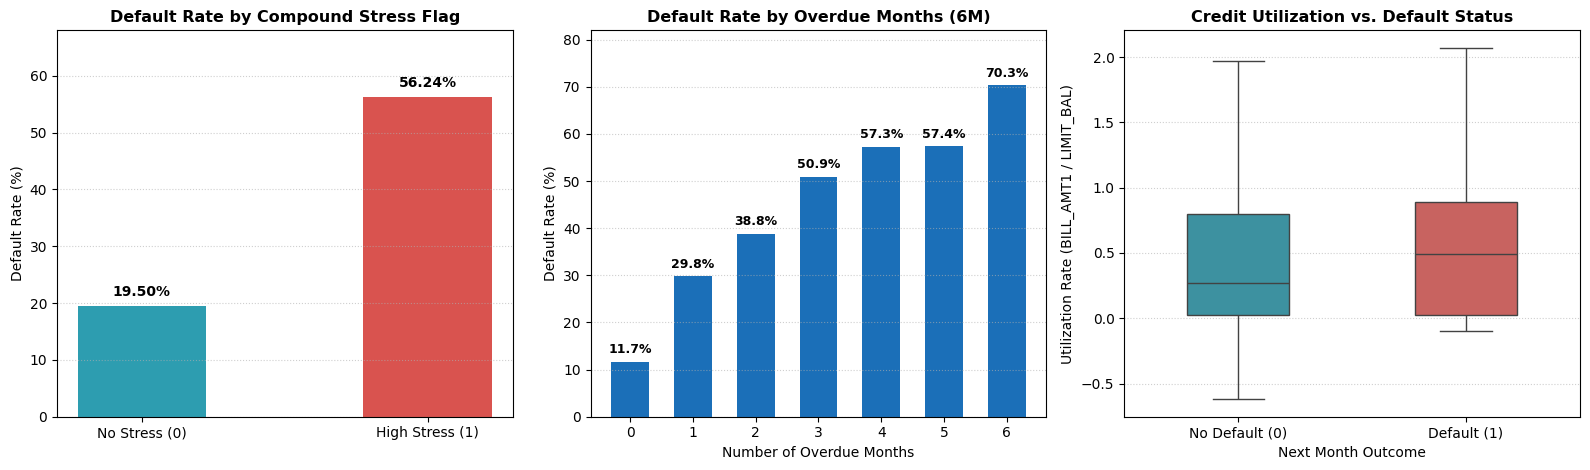

In [18]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))

# Plot 1: Default Rate by Compound Stress Flag
bars1 = ax1.bar(stress_summary.index, stress_summary["Default_Rate_Pct"], color=["#2D9DB0", "#D9534F"], width=0.45)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 1.2, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")
ax1.set_title("Default Rate by Compound Stress Flag", fontsize=11.5, fontweight="bold")
ax1.set_ylabel("Default Rate (%)", fontsize=10)
ax1.set_ylim(0, 68)
ax1.grid(axis="y", linestyle=":", alpha=0.6)

# Plot 2: Default Rate by 6-Month Overdue Frequency
bars2 = ax2.bar(overdue_summary.index.astype(str), overdue_summary["Default_Rate_Pct"], color="#1B6FB8", width=0.6)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 1.2, f"{yval:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=9)
ax2.set_title("Default Rate by Overdue Months (6M)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Number of Overdue Months", fontsize=10)
ax2.set_ylabel("Default Rate (%)", fontsize=10)
ax2.set_ylim(0, 82)
ax2.grid(axis="y", linestyle=":", alpha=0.6)

# Plot 3: Credit Utilization Rate vs. Default Status
sns.boxplot(
    x="default_next_month", y="utilization", data=analysis_df,
    showfliers=False, hue="default_next_month", palette=["#2D9DB0", "#D9534F"],
    legend=False, ax=ax3, width=0.45
)
ax3.set_title("Credit Utilization vs. Default Status", fontsize=11.5, fontweight="bold")
ax3.set_xticks([0, 1])
ax3.set_xticklabels(["No Default (0)", "Default (1)"])
ax3.set_xlabel("Next Month Outcome", fontsize=10)
ax3.set_ylabel("Utilization Rate (BILL_AMT1 / LIMIT_BAL)", fontsize=10)
ax3.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 6. Feature Dictionary & Technical Specifications
A comprehensive technical documentation of the engineered features, specifying their mathematical logic, data properties, operational bounds, and credit risk interpretations.

---

### Summary of Engineered Features

| Feature Name | Formula / Logic | Raw Inputs | Unit / Type | Timing |
| :--- | :--- | :--- | :--- | :--- |
| **`age_level`** | `pd.cut()` with bins `[20, 30, 40, 50, 90]` | `AGE` | Categorical (Ordinal) | Baseline snapshot |
| **`utilization`** | `BILL_AMT1 / LIMIT_BAL` | `BILL_AMT1`, `LIMIT_BAL` | Continuous Float | Current month profile |
| **`payment_to_bill_6m`** | `sum(PAY_AMT1..6) / sum(BILL_AMT1..6)` | `BILL_AMT1..6`, `PAY_AMT1..6` | Continuous Float | 6-month historical lookback |
| **`overdue_count_6m`** | `count_if(PAY_X > 0)` | `PAY_0`, `PAY_2` to `PAY_6` | Integer Count `[0-6]` | 6-month historical lookback |
| **`bill_change_recent`** | `BILL_AMT1 - BILL_AMT2` | `BILL_AMT1`, `BILL_AMT2` | Monetary (NTD) | Short-term velocity |
| **`bill_change_early`** | `BILL_AMT5 - BILL_AMT6` | `BILL_AMT5`, `BILL_AMT6` | Monetary (NTD) | Early warning velocity |
| **`log_limit_bal`** | `np.log1p(LIMIT_BAL)` | `LIMIT_BAL` | Transformed Float | Structural baseline |
| **`stress_flag`** | `high_utilization * recent_overdue` | `utilization`, `PAY_0` | Binary Indicator `[0, 1]` | Current month snapshot |

---

### Detailed Feature Specifications

#### 1. `age_level`
* **Missingness Policy:** No missing values expected based on the initial data audit (`Missing_Values = 0` for `AGE`). Any future unexpected null entries outside `[20, 90]` are captured as `NaN` for downstream categorical imputation.
* **Financial Interpretation:** Captures non-linear lifecycle risk. Younger cardholders (**'Young'**) typically lack extensive credit histories and stable income streams, demonstrating higher payment volatility compared to established career professionals (**'Adult'** / **'Middle-Aged'**) or retirees (**'Senior'**).

#### 2. `utilization`
* **Missingness Policy:** The data audit confirmed that `LIMIT_BAL` contains zero occurrences of `0`, guaranteeing safe division without `ZeroDivisionError` or infinite values.
* **Financial Interpretation:** Measures a borrower's reliance on revolving credit and remaining liquidity buffer. Elevated utilization indicates heavy debt dependency and financial stretching, correlating strongly with higher default incidence as demonstrated in the boxplot above.

#### 3. `payment_to_bill_6m`
* **Missingness Policy:** Zero-billed accounts over the 6-month window (`sum(BILL_AMT) == 0`) produce division infinities (`inf`), which are programmatically replaced with `np.nan` to represent inactive billing periods without distorting numerical distributions.
* **Financial Interpretation:** Captures aggregate repayment velocity. High ratios signify borrowers who actively clear statement balances, whereas persistently low ratios reveal cardholders making only minimum payments due to cash-flow constraints.

#### 4. `overdue_count_6m`
* **Missingness Policy:** Complete data availability across all six repayment status columns (`PAY_0`, `PAY_2`–`PAY_6`; note that `PAY_1` is omitted in the original UCI schema).
* **Financial Interpretation:** Measures chronic delinquency persistence. A monotonic rise in this count signals compounding repayment distress, acting as the strongest standalone predictor (climbing from **11.71%** at 0 overdue months to **70.32%** at 6 overdue months).

#### 5. `bill_change_recent` & `bill_change_early`
* **Missingness Policy:** Complete data availability across all historical billing statement streams.
* **Financial Interpretation:** Captures balance velocity dynamics. An escalating short-term delta (`bill_change_recent > 0`) reflects rapid debt accumulation or an immediate spending shock, while `bill_change_early` acts as an early-warning indicator of emerging financial strain months prior to formal delinquency.

#### 6. `log_limit_bal`
* **Missingness Policy:** Complete data availability. Using `np.log1p` executes $\log(1 + x)$, safeguarding against zero bounds.
* **Financial Interpretation:** Compresses the heavily right-skewed monetary scale of credit limits into a normalized distribution, preventing upper-tail outliers from dominating distance metrics or linear model weights.

#### 7. `stress_flag`
* **Missingness Policy:** Deterministic interaction feature that inherits missingness directly from `utilization` and `PAY_0`.
* **Financial Interpretation:** Isolates a severely distressed cohort where the borrower is simultaneously operating near maximum credit capacity ($\ge 80\%$) and missing their current payment deadline, isolating a sub-population with a **56.24% default rate**.


## 7. Data Leakage Prevention: Controlled Demonstration
Below we demonstrate why global preprocessing prior to train-test partitioning invalidates model evaluation.


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

mock_data = pd.DataFrame({
    "payment_to_bill_6m": [0.50, 0.20, np.nan, 0.10],
    "default_next_month": [0, 0, 1, 1]
})

print("Original Mock Dataset:")
display(mock_data)

imputer = SimpleImputer(strategy="mean")
leaked_features = imputer.fit_transform(mock_data[["payment_to_bill_6m"]])

X_train_leaked, X_test_leaked, y_train_m, y_test_m = train_test_split(
    leaked_features, mock_data["default_next_month"], test_size=0.5, random_state=42
)

print("\nX_train after Invalid Global Imputation:")
print(X_train_leaked)


Original Mock Dataset:


,payment_to_bill_6m,default_next_month
0,0.5,0
1,0.2,0
2,NaN,1
3,0.1,1



X_train after Invalid Global Imputation:
[[0.5       ]
 [0.26666667]]


**Why This Workflow Is Invalid:**  
By computing the imputation mean across the entire dataset prior to splitting, the missing value for the borrower assigned to `X_train` was replaced with `0.2667`—a statistic mathematically derived from observations sequestered in `X_test`. This directly leaks unseen test-set information into the training phase, violating sample independence, artificially inflating validation metrics, and degrading real-world generalization.

---

## 8. Feature Interpretations: Association vs. Causality
A rigorous economic and statistical evaluation of each engineered feature, explicitly decoupling historical statistical correlations (**Association**) from underlying behavioral mechanisms (**Causality**).

### 1. `age_level`
* **Association:** Younger age cohorts (`Young`) statistically exhibit higher default rates, acting as a demographic proxy for unobserved structural factors such as shorter credit tenure and lower savings buffers.
* **Causality:** Age itself does not *cause* default. Turning 25 does not trigger insolvency; the true causal drivers are underlying economic variables such as income volatility and limited liquid reserves.

### 2. `utilization`
* **Association:** High credit utilization exhibits a strong positive association with next-month default probability, as confirmed by the upward shift in the interquartile distribution of defaulted accounts.
* **Causality:** High utilization does not mechanically *cause* default; rather, it reflects elevated debt dependency. Causality stems from a cash-flow breaking point when monthly debt service obligations exceed disposable income.

### 3. `payment_to_bill_6m`
* **Association:** Low 6-month repayment ratios strongly correlate with imminent default risk, isolating borrowers who consistently roll over unpaid principal.
* **Causality:** Making minimum payments does not directly *cause* default. The causal mechanism resides in structural liquidity deficits where the borrower lacks sufficient cash flow to amortize principal, leaving them vulnerable to minor income shocks.

### 4. `overdue_count_6m`
* **Association:** Displays a strong, monotonic statistical association with default, rising from **11.71%** at zero overdue months to **70.32%** at six overdue months.
* **Causality:** A past delinquency does not physically *cause* a subsequent default; rather, recurring overdue statuses represent observable symptoms of an ongoing, unresolved solvency crisis carrying over across billing cycles.

### 5. `bill_change_recent` & `bill_change_early`
* **Association:** Rapidly expanding statement balances correlate with heightened default risk, capturing sudden expenditure spikes or accelerating debt reliance.
* **Causality:** A rising bill statement does not *cause* an account to fail. The causal driver is an unsustainable shock to the borrower's debt-to-income ratio when spending velocity outpaces income growth.

### 6. `log_limit_bal`
* **Association:** Lower credit limits are statistically associated with higher default rates because lenders assign tighter limits to riskier or unseasoned credit profiles during underwriting.
* **Causality:** Applying a logarithmic transformation has zero causal effect on borrower behavior; it is purely a mathematical scaling technique to stabilize gradient optimization and mitigate outlier leverage.

### 7. `stress_flag`
* **Association:** Isolates a severely distressed cohort exhibiting a **56.24% default rate**—nearly triple the baseline rate of unstressed accounts (**19.50%**).
* **Causality:** The binary indicator carries no causal force on its own. The underlying causal trigger is the **simultaneous convergence** of exhausted revolving credit capacity ($\ge 80\%$) and an active liquidity failure (`PAY_0 > 0`), eliminating any remaining financial buffer.

---

## 9. Analytical & Methodological Questions

#### 1. Why is `payment_to_bill_6m` not interchangeable with `utilization`?
* **Answer:** They capture distinct dimensions of credit risk. `utilization` is a static, point-in-time structural stock metric measuring current debt load relative to credit capacity, whereas `payment_to_bill_6m` is a dynamic, behavioral flow metric measuring repayment velocity over a 6-month horizon. A cardholder can maintain high utilization while consistently paying down statements in full each month, or conversely hold low utilization while failing to make payments.

#### 2. What information is lost when a continuous variable is replaced by a binary flag?
* **Answer:** Discretizing a continuous feature into a binary flag discards within-group variance, magnitude, and tail severity. Thresholding utilization at $\ge 80\%$ treats a borrower at 81% capacity identically to one over-limit at 120%, collapsing a continuous spectrum of escalating financial strain into a step function.

#### 3. Why must a rolling feature be computed within the entity and in time order?
* **Answer:** Grouping strictly by entity (`ID`) prevents cross-contamination of financial histories across distinct borrowers, while sorting chronologically from oldest to newest preserves causal temporal ordering and eliminates lookahead bias from future billing cycles.

#### 4. When would a maximum be more appropriate than a count?
* **Answer:** A maximum (`max`) is preferable to a count when measuring **delinquency severity** rather than frequency. A borrower who falls 90 days past due once (`max = 3`) typically poses higher loss-given-default risk than a borrower who pays 1–2 days late three times (`count = 3`, `max = 1`).

#### 5. Which feature definitions would change if the prediction point moved one month earlier?
* **Answer:** Every lag-dependent feature would shift backward by one period ($t-1$). Current `utilization` would use `BILL_AMT2 / LIMIT_BAL`, `bill_change_recent` would become `BILL_AMT2 - BILL_AMT3`, and 6-month rolling features (`overdue_count_6m` and `payment_to_bill_6m`) would drop the September snapshot (`PAY_0`, `BILL_AMT1`, `PAY_AMT1`) and incorporate Month 7 to maintain a 6-month lookback window.

---

## 10. AI Disclosure
*The feature engineering logic, statistical criteria, and risk modeling design were conceptualized and directed by the author. Generative AI tooling was utilized in a complementary assistant capacity to optimize code efficiency, structure Markdown documentation tables, and streamline plotting syntax. All data audits, code executions, and domain-specific financial interpretations were independently verified.*
